In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project folder
PROJECT_ROOT = Path(r"E:\da projects\Customer_Churn_Analysis")

# Dataset location
file_path = PROJECT_ROOT / "data" / "cleaned" / "customer_churn_cleaned.csv"

# Check whether file exists
print(file_path.exists())

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

True
Dataset loaded successfully!


In [2]:
df.shape

(7043, 21)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.50,No


In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
customerID          7043 non-null object
gender              7043 non-null object
SeniorCitizen       7043 non-null int64
Partner             7043 non-null object
Dependents          7043 non-null object
tenure              7043 non-null int64
PhoneService        7043 non-null object
MultipleLines       7043 non-null object
InternetService     7043 non-null object
OnlineSecurity      7043 non-null object
OnlineBackup        7043 non-null object
DeviceProtection    7043 non-null object
TechSupport         7043 non-null object
StreamingTV         7043 non-null object
StreamingMovies     7043 non-null object
Contract            7043 non-null object
PaperlessBilling    7043 non-null object
PaymentMethod       7043 non-null object
MonthlyCharges      7043 non-null float64
TotalCharges        7043 non-null float64
Churn               7043 non-null object
dtypes: float64(2), int64(2), ob

In [7]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [8]:
df.dtypes.value_counts()

object     17
float64     2
int64       2
dtype: int64

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.duplicated().sum()

0

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [12]:
df.describe(include=['object', 'category'])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,3068-OMWZA,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


In [13]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,3068-OMWZA,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2279.734304,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.794470,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,0.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,398.550000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1394.550000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3786.600000,NaN


In [14]:
df.select_dtypes (include=['int64', 'float64'])


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


In [15]:
df.select_dtypes(include=['object'])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


In [16]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [17]:
df[["tenure","MonthlyCharges","TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


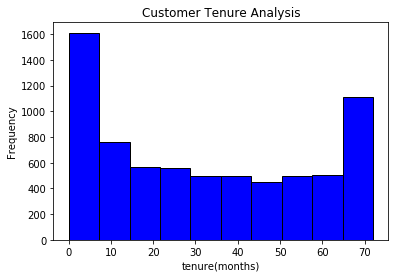

In [18]:
df["tenure"].plot(
    kind = "hist", bins =10, edgecolor='black', color='blue')
plt.title("Customer Tenure Analysis")
plt.xlabel('tenure(months)')
plt.ylabel('Frequency')
plt.show()

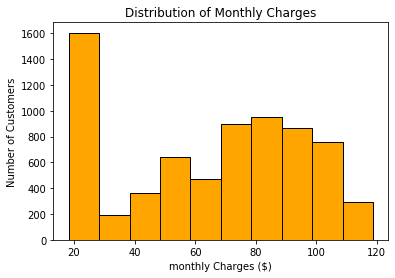

In [19]:
df["MonthlyCharges"].plot(
    kind = "hist", bins =10, edgecolor='black', color='orange')
plt.title("Distribution of Monthly Charges")
plt.xlabel('monthly Charges ($)') 
plt.ylabel('Number of Customers')
plt.show()

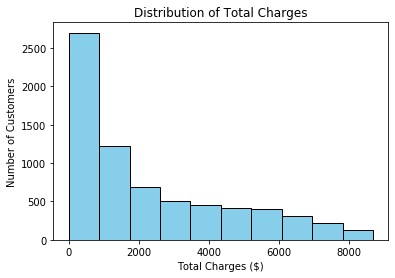

In [20]:
df["TotalCharges"].plot(
    kind = "hist", bins =10, edgecolor='black', color='skyblue')
plt.title("Distribution of Total Charges")
plt.xlabel('Total Charges ($)') 
plt.ylabel('Number of Customers')
plt.show()

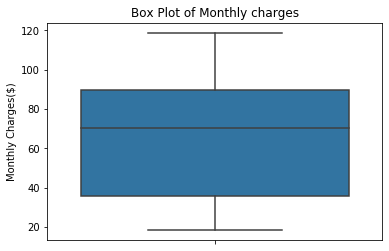

In [21]:
sns.boxplot(y=df['MonthlyCharges'])
plt.title('Box Plot of Monthly charges')
plt.ylabel('Monthly Charges($)')
plt.show()

In [22]:
q1=df['MonthlyCharges'].quantile(0.25)
q3=df['MonthlyCharges'].quantile(0.75)
iqr=q3-q1
lower_boundary = q1 - (1.5*iqr)
upper_boundary = q3 + (1.5*iqr)
print(f"Q1 (25th percentile): {q1:.2f}")
print(f"Q3 (75th percentile): {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower Boundary: {lower_boundary:.2f}")
print(f"upper Boundary: {upper_boundary:0.2f}")

Q1 (25th percentile): 35.50
Q3 (75th percentile): 89.85
IQR: 54.35
Lower Boundary: -46.02
upper Boundary: 171.38


In [23]:
outliers = df[(df['MonthlyCharges'] < lower_boundary) | (df['MonthlyCharges'] > upper_boundary)]
num_outliers = len(outliers)
print(f"Number of MonthlyCharges outliers: {num_outliers}")

Number of MonthlyCharges outliers: 0


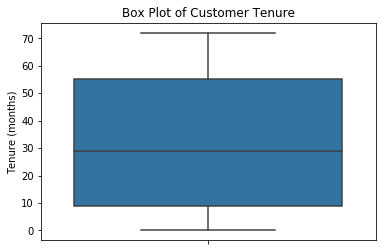

Tenure Q1: 9.00
Tenure Q3: 55.00
Tenure IQR: 46.00
Tenure Lower Boundary: -60.00
Tenure Upper Boundary: 124.00
Number of Tenure Outliers: 0


In [24]:
sns.boxplot(y=df['tenure'])
plt.title('Box Plot of Customer Tenure')
plt.ylabel('Tenure (months)')
plt.show()

tenure_q1 = df['tenure'].quantile(0.25)
tenure_q3 = df['tenure'].quantile(0.75)
tenure_iqr = tenure_q3 - tenure_q1
tenure_lower_boundary = tenure_q1 - (1.5 * tenure_iqr)
tenure_upper_boundary = tenure_q3 + (1.5 * tenure_iqr)

tenure_outliers = df[(df['tenure'] < tenure_lower_boundary) | (df['tenure'] > tenure_upper_boundary)]
num_tenure_outliers = len(tenure_outliers)

print(f"Tenure Q1: {tenure_q1:.2f}")
print(f"Tenure Q3: {tenure_q3:.2f}")
print(f"Tenure IQR: {tenure_iqr:.2f}")
print(f"Tenure Lower Boundary: {tenure_lower_boundary:.2f}")
print(f"Tenure Upper Boundary: {tenure_upper_boundary:.2f}")
print(f"Number of Tenure Outliers: {num_tenure_outliers}")

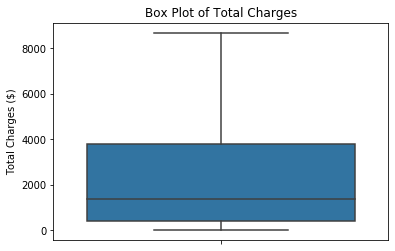

TotalCharges Q1: 398.55
TotalCharges Q3: 3786.60
TotalCharges IQR: 3388.05
TotalCharges Lower Boundary: -4683.52
TotalCharges Upper Boundary: 8868.67
Number of TotalCharges Outliers: 0


In [25]:
sns.boxplot(y=df['TotalCharges'])
plt.title('Box Plot of Total Charges')
plt.ylabel('Total Charges ($)')
plt.show()

total_q1 = df['TotalCharges'].quantile(0.25)
total_q3 = df['TotalCharges'].quantile(0.75)

total_iqr = total_q3 - total_q1

total_lower_boundary = total_q1 - (1.5 * total_iqr)
total_upper_boundary = total_q3 + (1.5 * total_iqr)

total_outliers = df[(df['TotalCharges'] < total_lower_boundary) | (df['TotalCharges'] > total_upper_boundary)]
num_total_outliers = len(total_outliers)

print(f"TotalCharges Q1: {total_q1:.2f}")
print(f"TotalCharges Q3: {total_q3:.2f}")
print(f"TotalCharges IQR: {total_iqr:.2f}")
print(f"TotalCharges Lower Boundary: {total_lower_boundary:.2f}")
print(f"TotalCharges Upper Boundary: {total_upper_boundary:.2f}")
print(f"Number of TotalCharges Outliers: {num_total_outliers}")

#The IQR method was applied to tenure, MonthlyCharges and TotalCharges. No potential outliers were identified in any of the three numerical columns. Although TotalCharges showed a right-skewed distribution, its maximum value remained within the calculated upper boundary. Therefore, no records were removed based on outlier detection.

In [26]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


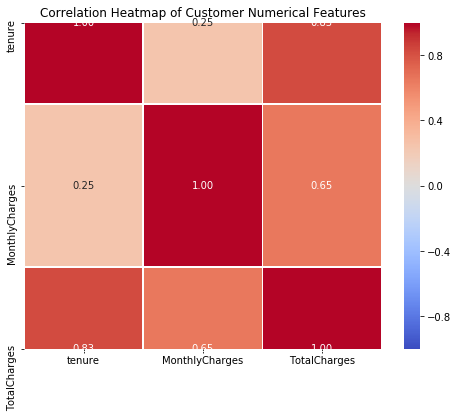

In [27]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
corr_matrix = df[numerical_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Customer Numerical Features')
plt.show()

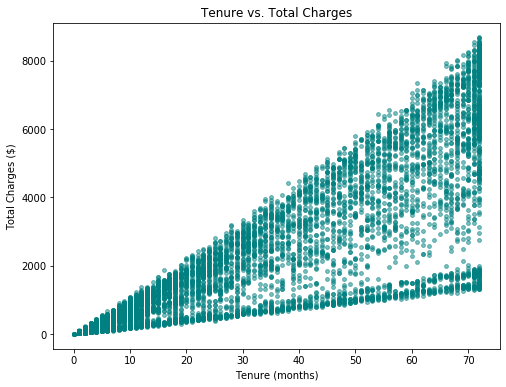

In [28]:
plt.figure(figsize=(8, 6))
plt.scatter(df['tenure'], df['TotalCharges'], alpha=0.5, s=15, color='teal')
plt.title('Tenure vs. Total Charges')
plt.xlabel('Tenure (months)')
plt.ylabel('Total Charges ($)')
plt.show()

#Tenure and TotalCharges demonstrate a strong positive correlation (0.8262). Customers with longer tenures generally accumulate higher total charges. However, the variation in TotalCharges at similar tenure levels suggests that monthly pricing also influences accumulated charges.

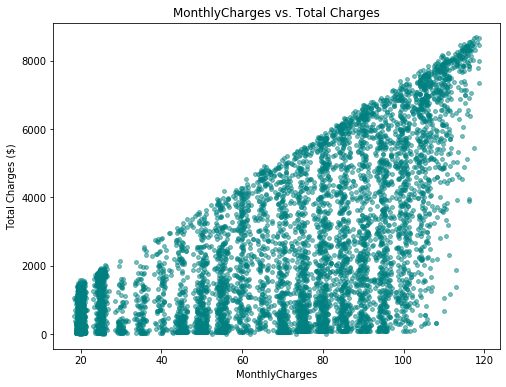

In [29]:
plt.figure(figsize=(8, 6))
plt.scatter(df['MonthlyCharges'],df['TotalCharges'], alpha=0.5, s=15, color='teal')
plt.title('MonthlyCharges vs. Total Charges')
plt.xlabel('MonthlyCharges')
plt.ylabel('Total Charges ($)')
plt.show()

In [30]:
avg_tenure = df.groupby('Churn')['tenure'].mean()
print(avg_tenure)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [31]:
avg_Mcharges = df.groupby('Churn')['MonthlyCharges'].mean()
print(avg_Mcharges)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [32]:
avg_Tcharges = df.groupby('Churn')['TotalCharges'].mean()
print(avg_Tcharges)

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64


In [33]:
pd.crosstab(df['Contract'],df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [34]:
contract_churn_pct= pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100
print(contract_churn_pct)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [35]:
pd.crosstab(df['InternetService'],df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [36]:
itsrvc_churn_pct= pd.crosstab(df['InternetService'],df['Churn'],normalize='index')*100
print(itsrvc_churn_pct)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [37]:
pd.crosstab(df['PaymentMethod'],df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [38]:
pmtd_churn_pct= pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100
print(pmtd_churn_pct)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [39]:
pd.crosstab(df['TechSupport'],df['Churn'])

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


In [40]:
tchspt_churn_pct= pd.crosstab(df['TechSupport'],df['Churn'],normalize='index')*100
print(tchspt_churn_pct)

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


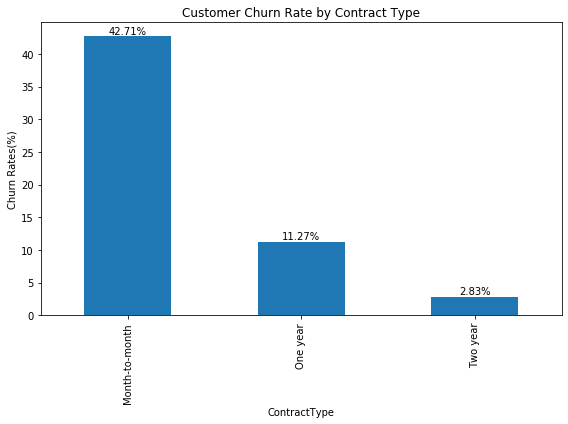

In [41]:
churn_rates = contract_churn_pct['Yes']
ax = churn_rates.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("ContractType")
plt.ylabel("Churn Rates(%)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


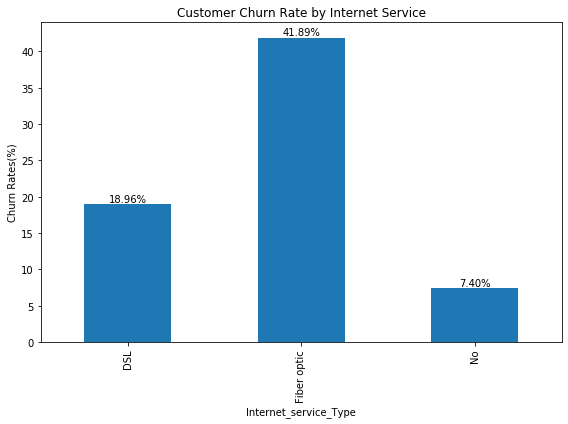

In [42]:
churn_rates = itsrvc_churn_pct['Yes']
ax = churn_rates.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet_service_Type")
plt.ylabel("Churn Rates(%)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

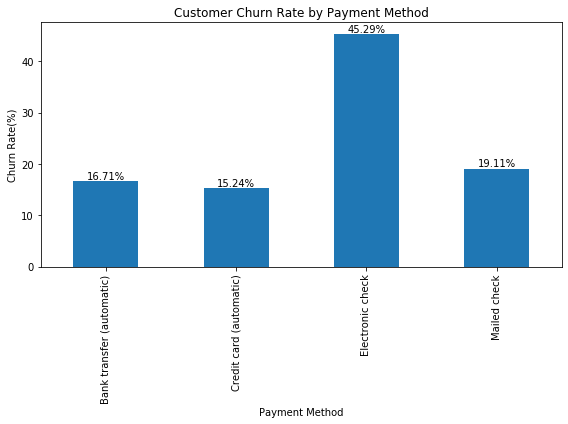

In [43]:
churn_rates=pmtd_churn_pct['Yes']
ax = churn_rates.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate(%)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


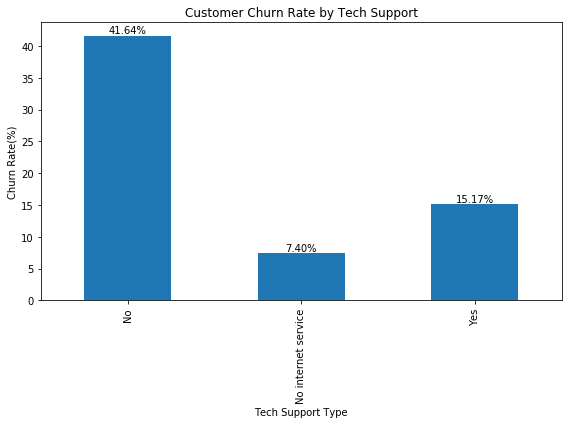

In [44]:
churn_rates=tchspt_churn_pct['Yes']
ax = churn_rates.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support Type")
plt.ylabel("Churn Rate(%)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


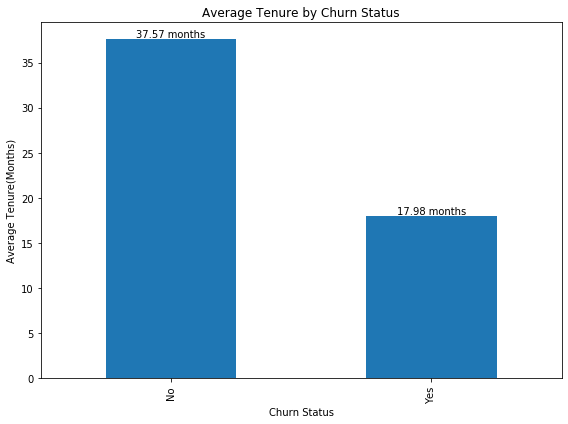

In [45]:
churn_status = avg_tenure
ax = churn_status.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Average Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Tenure(Months)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f} months',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

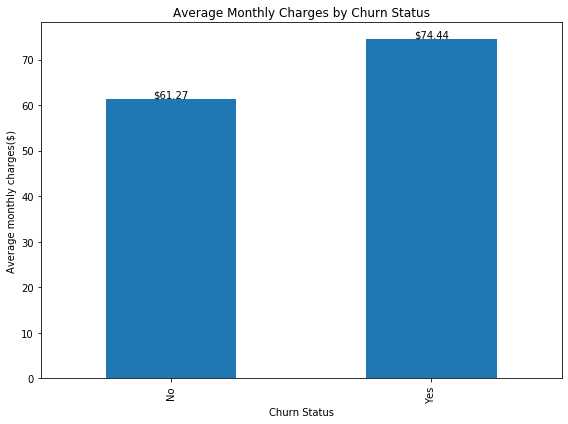

In [46]:
churn_status = avg_Mcharges
ax = churn_status.plot(
    kind="bar",
    figsize=(8,6)
)
plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average monthly charges($)")
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'${height:.2f}',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()